In [ ]:
# Importación de bibliotecas necesarias

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt
from scipy.signal import firwin, freqz, filtfilt

print("Bibliotecas cargadas correctamente")

Bibliotecas cargadas correctamente


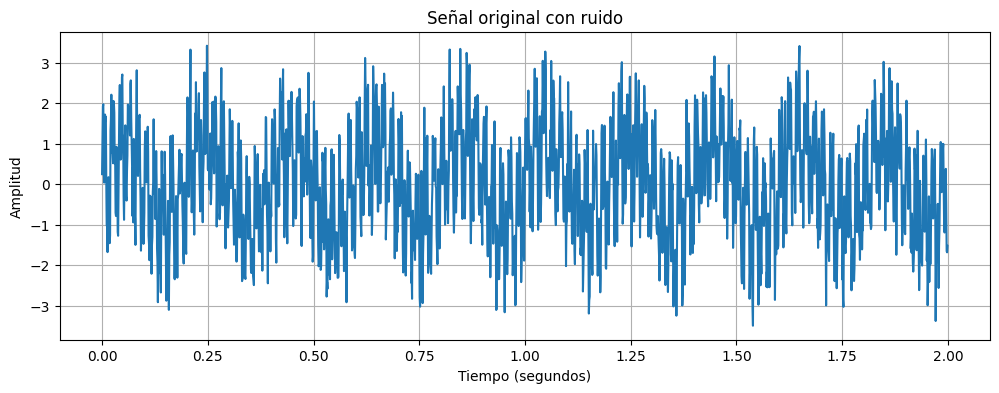

In [ ]:
# Parámetros de la señal

fs = 1000
duracion = 2

t = np.arange(0, duracion, 1/fs)

# Generación de señales de diferentes frecuencias

frecuencia_baja = np.sin(2*np.pi*5*t)
frecuencia_media = np.sin(2*np.pi*50*t)
frecuencia_alta = np.sin(2*np.pi*150*t)

# Generación de ruido blanco

np.random.seed(42)
ruido = 0.5 * np.random.randn(len(t))

# Señal original compuesta

senal = (
    frecuencia_baja +
    frecuencia_media +
    frecuencia_alta +
    ruido
)

# Gráfica de la señal original

plt.figure(figsize=(12,4))

plt.plot(t, senal)

plt.title("Señal original con ruido")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.grid()
plt.show()

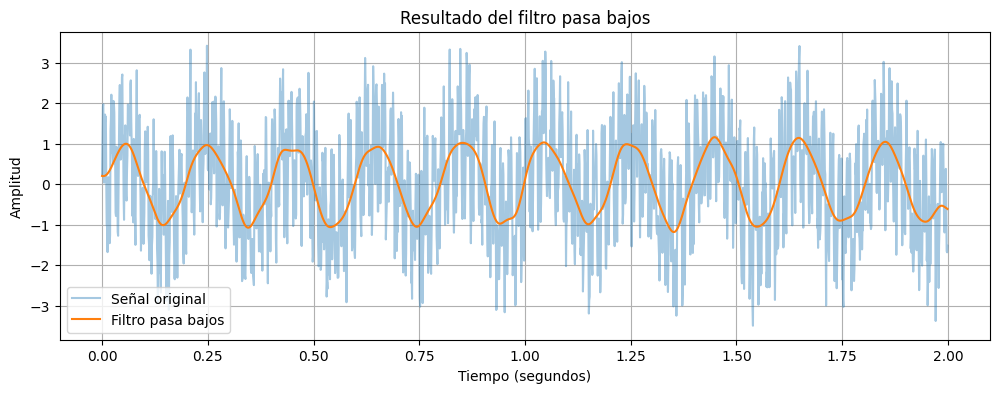

In [ ]:
# DISEÑO DEL FILTRO PASA BAJOS

# Filtro IIR Butterworth
sos_bajos = butter(
    4, 20,
    btype='lowpass',
    fs=fs,
    output='sos'
)

# Aplicación del filtro
senal_bajos = sosfiltfilt(sos_bajos, senal)

# Gráfica
plt.figure(figsize=(12,4))

plt.plot(t, senal, alpha=0.4, label="Señal original")
plt.plot(t, senal_bajos, label="Filtro pasa bajos")

plt.title("Resultado del filtro pasa bajos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid()
plt.show()

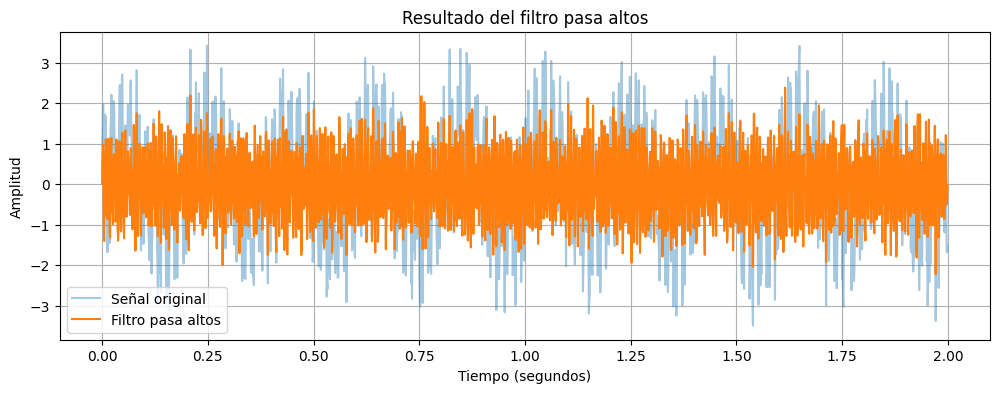

In [ ]:
# DISEÑO DEL FILTRO PASA ALTOS

# Filtro IIR Butterworth
sos_altos = butter(
    4, 80,
    btype='highpass',
    fs=fs,
    output='sos'
)

# Aplicación del filtro
senal_altos = sosfiltfilt(sos_altos, senal)

# Gráfica
plt.figure(figsize=(12,4))

plt.plot(t, senal, alpha=0.4, label="Señal original")
plt.plot(t, senal_altos, label="Filtro pasa altos")

plt.title("Resultado del filtro pasa altos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid()
plt.show()

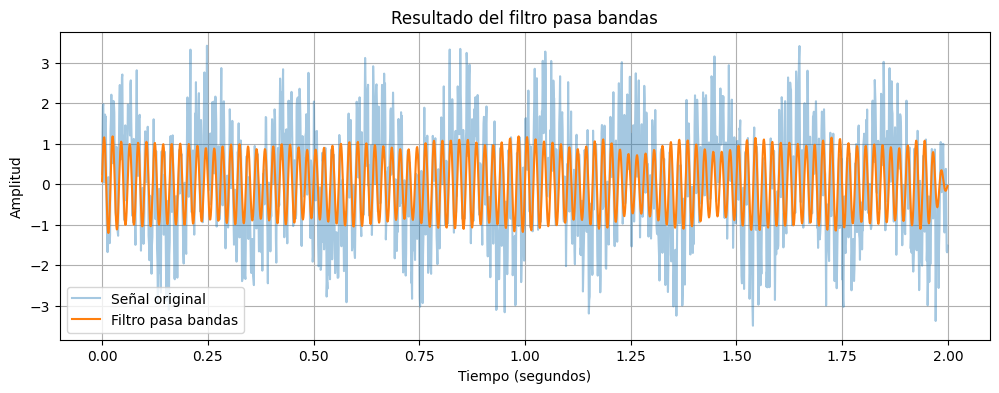

In [ ]:
# DISEÑO DEL FILTRO PASA BANDAS

# Filtro IIR Butterworth
sos_bandas = butter(
    4, [40, 60],
    btype='bandpass',
    fs=fs,
    output='sos'
)

# Aplicación del filtro
senal_bandas = sosfiltfilt(sos_bandas, senal)

# Gráfica
plt.figure(figsize=(12,4))

plt.plot(t, senal, alpha=0.4, label="Señal original")
plt.plot(t, senal_bandas, label="Filtro pasa bandas")

plt.title("Resultado del filtro pasa bandas")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid()
plt.show()

In [ ]:
# DISEÑO DE FILTROS FIR CON VENTANA HAMMING

# Filtro FIR pasa bajos
fir_bajos = firwin(
    101, 20,
    fs=fs,
    window='hamming'
)

# Filtro FIR pasa altos
fir_altos = firwin(
    101, 80,
    fs=fs,
    pass_zero=False,
    window='hamming'
)

# Filtro FIR pasa bandas
fir_bandas = firwin(
    101, [40, 60],
    fs=fs,
    pass_zero=False,
    window='hamming'
)

# Aplicación de los filtros FIR
resultado_fir_bajos = filtfilt(fir_bajos, 1, senal)
resultado_fir_altos = filtfilt(fir_altos, 1, senal)
resultado_fir_bandas = filtfilt(fir_bandas, 1, senal)

print("Los tres filtros FIR se aplicaron correctamente.")

Los tres filtros FIR se aplicaron correctamente.


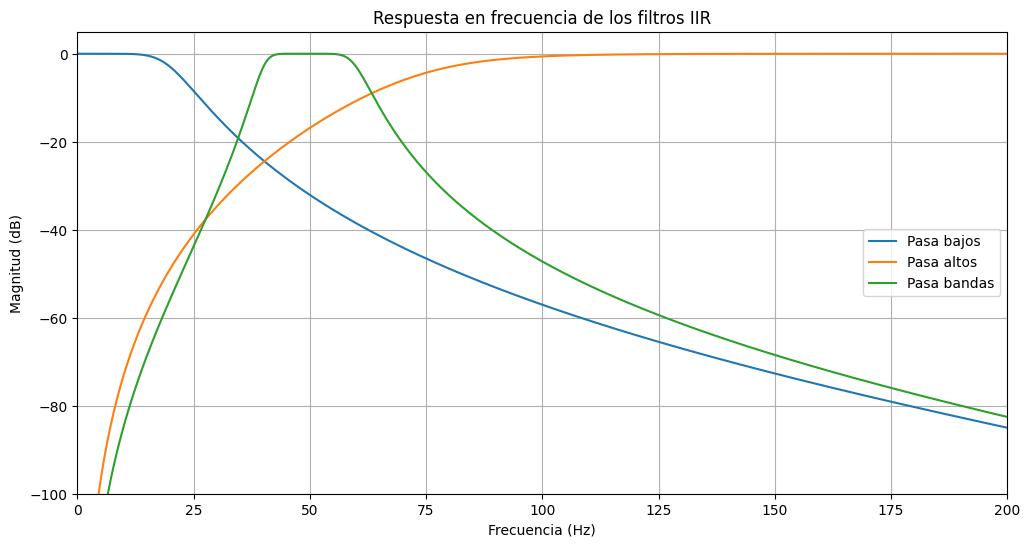

In [ ]:
# ANÁLISIS DE RESPUESTA EN FRECUENCIA

filtros = [
    ("Pasa bajos", sos_bajos),
    ("Pasa altos", sos_altos),
    ("Pasa bandas", sos_bandas)
]

plt.figure(figsize=(12,6))

for nombre, filtro in filtros:

    from scipy.signal import sosfreqz

    frecuencias, respuesta = sosfreqz(
        filtro,
        worN=2048,
        fs=fs
    )

    magnitud = 20*np.log10(
        np.maximum(np.abs(respuesta), 1e-10)
    )

    plt.plot(
        frecuencias,
        magnitud,
        label=nombre
    )

plt.title("Respuesta en frecuencia de los filtros IIR")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")

plt.xlim(0, 200)
plt.ylim(-100, 5)

plt.legend()
plt.grid()
plt.show()

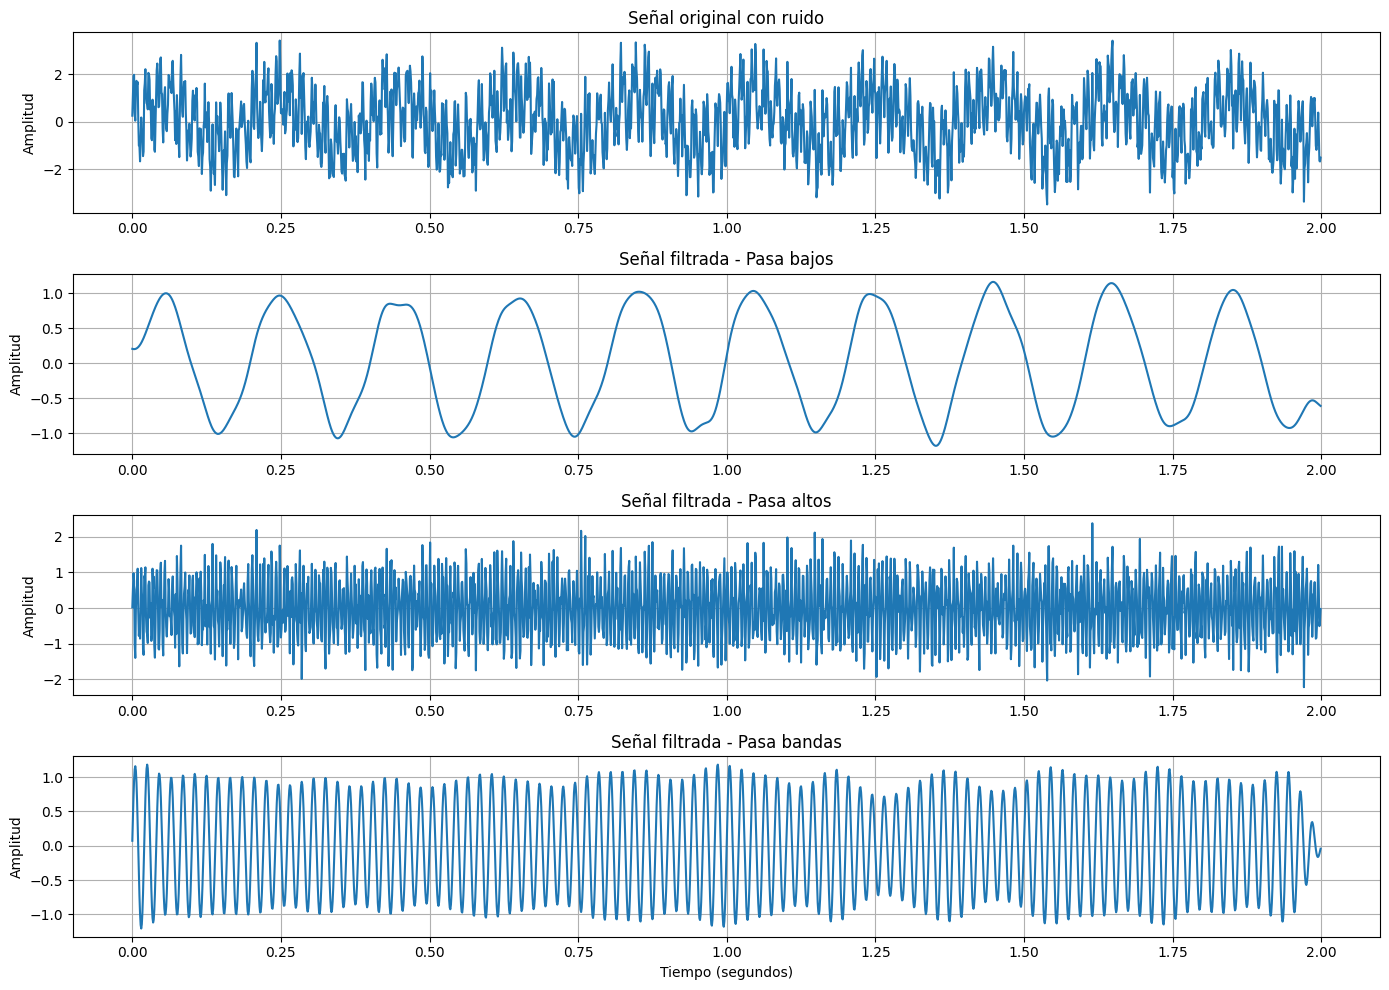

In [ ]:
# COMPARACIÓN DE RESULTADOS

plt.figure(figsize=(14,10))

plt.subplot(4,1,1)
plt.plot(t, senal)
plt.title("Señal original con ruido")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4,1,2)
plt.plot(t, senal_bajos)
plt.title("Señal filtrada - Pasa bajos")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4,1,3)
plt.plot(t, senal_altos)
plt.title("Señal filtrada - Pasa altos")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4,1,4)
plt.plot(t, senal_bandas)
plt.title("Señal filtrada - Pasa bandas")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid()

plt.tight_layout()
plt.show()